# Lab 02-05 · The Laplace Transform for ODEs

Companion to chapter [02-05](../../chapters/02-05-laplace-transform-for-odes.md). Handout: [README.md](README.md).

Run the cells in order. Cells marked **🔮 Predict** ask you to write a prediction *before* running.

In [1]:
import math, sys
from pathlib import Path
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy import signal
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass
t, s = sp.symbols("t s", positive=True)
L = lambda f: sp.laplace_transform(f, t, s, noconds=True)
iL = lambda F: sp.inverse_laplace_transform(F, s, t)

## Part 1 — Transforms by machine

SymPy checks the table and the properties derived in chapter §3.1–3.2.

In [2]:
a, w = sp.symbols("a omega", positive=True)
checks = {
    "1": (L(sp.Integer(1)), 1 / s),
    "e^{-at}": (L(sp.exp(-a * t)), 1 / (s + a)),
    "t^3": (L(t**3), 6 / s**4),
    "cos ωt": (L(sp.cos(w * t)), s / (s**2 + w**2)),
    "e^{-t} cos 3t": (L(sp.exp(-t) * sp.cos(3 * t)), (s + 1) / ((s + 1)**2 + 9)),
    "t e^{-2t}": (L(t * sp.exp(-2 * t)), 1 / (s + 2)**2),
}
for name, (got, want) in checks.items():
    print(f"{name:14s} {str(sp.simplify(got)):32s} matches table: {sp.simplify(got - want) == 0}")
f = sp.Function("f")
print("derivative rule:", L(sp.Derivative(f(t), t)))

1              1/s                              matches table: True
e^{-at}        1/(a + s)                        matches table: True
t^3            6/s**4                           matches table: True
cos ωt         s/(omega**2 + s**2)              matches table: True
e^{-t} cos 3t  (s + 1)/((s + 1)**2 + 9)         matches table: True
t e^{-2t}      (s + 2)**(-2)                    matches table: True
derivative rule: s*LaplaceTransform(f(t), t, s) - f(0)


## Part 2 — Partial fractions, by SymPy and by SciPy

**🔮 Predict:** how many terms does $1/(s^2(s + 1))$ split into, and what are their inverse transforms?

In [3]:
for F in [(s**2 + 5*s + 12) / (s*(s + 2)*(s + 3)), (s + 4) / (s**2 * (s + 2)), (3*s + 7) / (s**2 + 4*s + 13), 1 / (s**2 * (s + 1))]:
    print(f"{str(F):34s} = {sp.apart(F, s)}")
    print(f"{'':34s} -> y(t) = {sp.simplify(iL(F))}")

# SciPy: residues and poles of (s + 4)/(s^3 + 2 s^2) -- note the repeated pole at 0
r, p, k = signal.residue([1, 4], [1, 2, 0, 0])
print("\nscipy.signal.residue for (s + 4)/(s^2 (s + 2)):")
for ri, pi in zip(r, p):
    print(f"  residue {ri.real:+.4f} at pole {pi.real:+.4f}")

(s**2 + 5*s + 12)/(s*(s + 2)*(s + 3)) = 2/(s + 3) - 3/(s + 2) + 2/s
                                   -> y(t) = 2 - 3*exp(-2*t) + 2*exp(-3*t)
(s + 4)/(s**2*(s + 2))             = 1/(2*(s + 2)) - 1/(2*s) + 2/s**2
                                   -> y(t) = 2*t - 1/2 + exp(-2*t)/2
(3*s + 7)/(s**2 + 4*s + 13)        = (3*s + 7)/(s**2 + 4*s + 13)
                                   -> y(t) = (sin(3*t) + 9*cos(3*t))*exp(-2*t)/3
1/(s**2*(s + 1))                   = 1/(s + 1) - 1/s + s**(-2)
                                   -> y(t) = t - 1 + exp(-t)

scipy.signal.residue for (s + 4)/(s^2 (s + 2)):
  residue -0.5000 at pole +0.0000
  residue +2.0000 at pole +0.0000
  residue +0.5000 at pole -2.0000


SciPy lists a repeated pole once per multiplicity: the residues −0.5 and 2 at $s = 0$ are the coefficients of $1/s$ and $1/s^2$ (Problem 02-05.5).

## Part 3 — Poles and modes

**🔮 Predict:** what happens to the impulse response as a pole pair moves toward the imaginary axis?

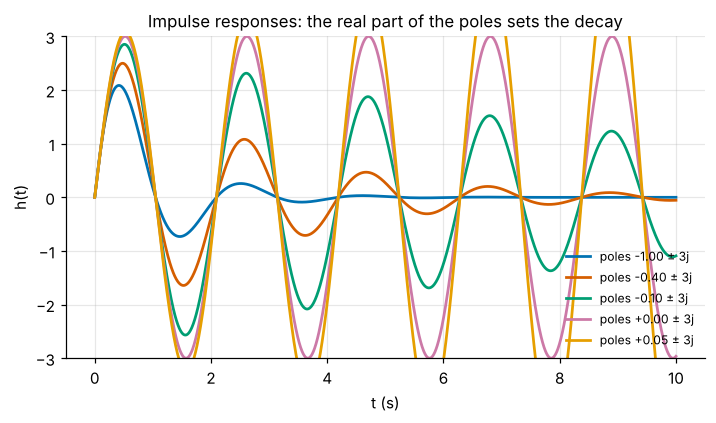

In [4]:
tt = np.linspace(0, 10, 2000)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for sigma in (-1.0, -0.4, -0.1, 0.0, 0.05):
    poles = [complex(sigma, 3), complex(sigma, -3)]
    den = np.real(np.poly(poles))
    tout, h = signal.impulse(([9 + sigma**2], den), T=tt)
    ax.plot(tout, h, label=f"poles {sigma:+.2f} ± 3j")
ax.set_xlabel("t (s)"); ax.set_ylabel("h(t)"); ax.set_ylim(-3, 3); ax.legend(fontsize=8)
ax.set_title("Impulse responses: the real part of the poles sets the decay"); plt.show()

The imaginary part (3 rad/s) fixes the ringing frequency; the real part sets the envelope $e^{\sigma t}$: decaying for σ < 0, constant at σ = 0 and growing for σ > 0.

## Part 4 — The final-value trap

The theorem's answer is compared with the actual long-time value.

In [5]:
cases = {
    "(s²+5s+12)/(s(s+2)(s+3))  (stable)": (s**2 + 5*s + 12) / (s*(s + 2)*(s + 3)),
    "1/(s - 1)  (unstable)": 1 / (s - 1),
    "2/(s^2 + 4)  (oscillating)": 2 / (s**2 + 4),
    "4/(s(s^2 - s + 2))  (unstable)": 4 / (s*(s**2 - s + 2)),
}
for name, F in cases.items():
    fvt = sp.limit(s * F, s, 0)
    y = sp.lambdify(t, iL(F), "numpy")
    print(f"{name:34s} FVT says {str(fvt):4s}  y(20) = {complex(y(20.0)).real:.4g}")

(s²+5s+12)/(s(s+2)(s+3))  (stable) FVT says 2     y(20) = 2
1/(s - 1)  (unstable)              FVT says 0     y(20) = 4.852e+08
2/(s^2 + 4)  (oscillating)         FVT says 0     y(20) = 0.7451
4/(s(s^2 - s + 2))  (unstable)     FVT says 2     y(20) = 5422


Only the first case is trustworthy: the others have poles on or to the right of the imaginary axis, where the theorem's condition fails.

## Part 5 — ngspice

From the repository root, run `python tools/run_spice.py 02-05`:

- `rlc_step_vs_sxfer.cir`: the step response of Example 02-05.3, once as an R-L-C circuit and once as an XSPICE `s_xfer` block that implements $H(s) = 10^8/(s^2 + 5000s + 10^8)$ directly. Both overshoot by 44.43% at 0.3245 ms.
- `rc_pulse.cir`: the pulse of Example 02-05.4 (4.323 V at 2 ms, 1.590 V at 3 ms).

## Your turn

1. In Part 2, invert $\dfrac{s^3 + 1}{s(s + 1)^2}$. Why does SymPy's answer contain a delta function? (Hint: is the fraction proper?)
2. Edit the `s_xfer` block's denominator so its poles sit at $-1000 \pm j9950$ and predict the new overshoot before re-running.